# 04 — Q1 Revenue Drift (revised)
**Week 4 — CadetX Heavy Supplier, Inventory & Warehouse Analytics**

**Locked question (Q1).** Net revenue is flat to slightly declining (₹3.87B in 2019 to ₹3.68B in 2024) while order count is steady (about 3,000 a year). Average order value drifted from ₹1.28M to ₹1.24M. Is this pricing, product mix or demand?

**Source:** the corrected Week-2 merged datasets `sales_orders_full.csv` (130,402 lines, 20,000 orders) and `invoices_with_payments.csv` (18,033 invoices), plus the Week-3 `kpi_revenue_by_year.csv` as the baseline to reproduce.

### What changed from the first Q1 version
| # | Change | Why |
|---|---|---|
| 1 | **Revenue is reconciled before it is analysed**: placed value, cancelled value and net revenue are tied out for every year, and net revenue is cross-checked against the invoice table | The first version started from net revenue without showing how cancellations enter it |
| 2 | **Year basis is tested, not assumed**: order-date year is compared with delivery-date year, and every year is confirmed to contain all 12 months | A partial year or a year-boundary effect would look like a decline |
| 3 | **Findings are graded**: *supported*, *not distinguishable from noise* (withdrawn as findings), or *indicative* (depends on an external assumption) | The first version described the average-order-value drift and the product-mix shift as findings; neither survives a significance test |
| 4 | **Real-terms result moved from headline to "indicative"**, with a sensitivity band instead of one number | It rests on a general CPI series, not a parts price index |
| 5 | **Week 3 wording refined**: "order volume is steady, so the decline comes from value per order" is split into delivered orders and average order value | Placed orders are steady, but delivered orders fell 2.5% because of cancellations |
| 6 | **23 integrity checks**: every figure is asserted (row counts, key uniqueness, header = lines, totals tie to Week 3 and to invoices); the run stops if any check fails; results are written to `validation_report_week04_q1.csv` | Same discipline as Week 3 |
| 7 | **Open items with owners** for what the data cannot answer | Price list frozen, no cancellation reason, no discount field, no parts price index |

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# ── Paths: the notebook looks for the merged files next to itself, then in the repository layout ──────────
import os
def find_dir(env_var, marker, rels):
    """Look in an environment variable first, then in this folder and every parent folder, using the repository layout."""
    if os.environ.get(env_var) and (Path(os.environ[env_var]) / marker).exists():
        return Path(os.environ[env_var])
    for base in [Path.cwd(), *Path.cwd().parents]:
        for rel in rels:
            if (base / rel / marker).exists():
                return base / rel
    return None
DATA_DIR = find_dir("CADETX_MERGED", "sales_orders_full.csv",
                    ["merged", "data/merged", "week-02/reports/week_02/merged", "reports/week_02/merged"])
KPI_DIR = find_dir("CADETX_KPI", "kpi_revenue_by_year.csv", ["kpi_outputs", "week-03/kpi_outputs"])
assert DATA_DIR is not None, "Could not find the merged datasets. Run from inside the repository, put a merged/ folder next to the notebook, or set the CADETX_MERGED environment variable to the folder."
assert KPI_DIR is not None, "Could not find the Week-3 kpi_outputs. Run from inside the repository, put a kpi_outputs/ folder next to the notebook, or set the CADETX_KPI environment variable to the folder."
OUT_DIR = Path("q1_outputs");  OUT_DIR.mkdir(exist_ok=True)
CHART_DIR = Path("q1_charts"); CHART_DIR.mkdir(exist_ok=True)
print("Merged datasets :", DATA_DIR.resolve())
print("Week-3 baseline :", KPI_DIR.resolve())

def save(df, name, index=False):
    df.to_csv(OUT_DIR / name, index=index); print(f"saved {name} ({len(df)} rows)")
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(CHART_DIR / name, dpi=130, facecolor=fig.get_facecolor()); plt.show(); plt.close(fig); print("saved chart", name)

# ── Chart style (same palette and conventions as the Week 3 charts) ─────────────────────────────────────
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8, "axes.axisbelow": True,
    "legend.frameon": False, "font.size": 9.5, "figure.dpi": 110})
def figs(nrows=1, ncols=1, size=(11, 4.2), **kw):
    fig, axs = plt.subplots(nrows, ncols, figsize=size, **kw); return fig, axs
def billions(ax, axis="y", dec=1):
    f = FuncFormatter(lambda v, _: f"₹{v:,.{dec}f}B")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(f)
def inr_b(x): return f"₹{x/1e9:,.2f}B"
def inr_m(x): return f"₹{x/1e6:,.1f}M"

checks = []   # (check, expected, actual, status) -> validation report; the run stops at the first failure
def check(name, expected, actual, ok):
    checks.append((name, expected, actual, "PASS" if ok else "FAIL")); assert ok, name

Merged datasets : /tmp/claude-0/-home-claude/e17ce6b6-afe8-5a4a-b191-c5fe2b31efe5/scratchpad/portable/week-02/reports/week_02/merged
Week-3 baseline : /tmp/claude-0/-home-claude/e17ce6b6-afe8-5a4a-b191-c5fe2b31efe5/scratchpad/portable/week-03/kpi_outputs


## 0. Load & integrity checks

In [2]:
sales = pd.read_csv(DATA_DIR / "sales_orders_full.csv", low_memory=False, parse_dates=["order_date", "delivery_date"])
inv = pd.read_csv(DATA_DIR / "invoices_with_payments.csv", low_memory=False, parse_dates=["order_date"])
ref = pd.read_csv(KPI_DIR / "kpi_revenue_by_year.csv").set_index("order_year")

check("sales rows (line grain)", 130402, len(sales), len(sales) == 130402)
check("sales key (so_id,line_number) unique", 0, int(sales.duplicated(["so_id", "line_number"]).sum()), not sales.duplicated(["so_id", "line_number"]).any())
check("unique orders", 20000, sales.so_id.nunique(), sales.so_id.nunique() == 20000)
check("invoice rows", 18033, len(inv), len(inv) == 18033)
amb = [c for df in (sales, inv) for c in df.columns if c.endswith(("_x", "_y", "_dim"))]
check("no ambiguous _x/_y columns", 0, len(amb), len(amb) == 0)
print(pd.DataFrame(checks, columns=["check", "expected", "actual", "status"]).to_string(index=False))

                               check  expected  actual status
             sales rows (line grain)    130402  130402   PASS
sales key (so_id,line_number) unique         0       0   PASS
                       unique orders     20000   20000   PASS
                        invoice rows     18033   18033   PASS
          no ambiguous _x/_y columns         0       0   PASS


# Part A — What exactly is "revenue" here?

### Definitions (same as Week 3, used throughout)
| Term | Definition |
|---|---|
| **Net revenue** | `total_order_value` (ex-GST) of **Delivered** orders |
| **Placed value** | `total_order_value` (ex-GST) of **all** orders placed (Delivered + Cancelled) |
| **Cancelled value** | ex-GST value of Cancelled orders. Reported separately, **never** counted as revenue |
| **Year** | Calendar year of `order_date` (tested in A.3) |

By construction **net revenue = placed value − cancelled value**. Every Delivered order has one invoice and every Cancelled order has none.

In [3]:
orders = sales.drop_duplicates("so_id").copy()
orders["order_year"] = orders.order_date.dt.year
orders["order_month"] = orders.order_date.dt.to_period("M")

# header totals must equal the sum of the lines
line_sum = sales.groupby("so_id").line_total.sum()
hdr_gap = (orders.set_index("so_id").total_order_value - line_sum).abs()
check("order header total == sum of lines (all orders)", 0, int((hdr_gap > 1).sum()), (hdr_gap <= 1).all())

deliv = orders[orders.order_status == "Delivered"].copy()
cancel = orders[orders.order_status == "Cancelled"].copy()
sales_d = sales[sales.order_status == "Delivered"].copy()
sales_d["order_year"] = sales_d.order_date.dt.year
check("delivered + cancelled == all orders", 20000, len(deliv) + len(cancel), len(deliv) + len(cancel) == 20000)
check("net revenue (delivered lines) == delivered order totals", 0,
      round(sales_d.line_total.sum() - deliv.total_order_value.sum(), 2),
      abs(sales_d.line_total.sum() - deliv.total_order_value.sum()) < 1)
print(orders.order_status.value_counts().to_string())

order_status
Delivered    18033
Cancelled     1967


### A.1 Tie-out: placed value, cancelled value and net revenue, by year

In [4]:
chain = pd.DataFrame({
    "orders_placed": orders.groupby("order_year").size(),
    "orders_delivered": deliv.groupby("order_year").size(),
    "placed_value": orders.groupby("order_year").total_order_value.sum(),
    "cancelled_value": cancel.groupby("order_year").total_order_value.sum(),
    "net_revenue": deliv.groupby("order_year").total_order_value.sum(),
})
chain["orders_cancelled"] = chain.orders_placed - chain.orders_delivered
chain["cancellation_rate_pct"] = chain.orders_cancelled / chain.orders_placed * 100
chain["cancelled_pct_of_placed_value"] = chain.cancelled_value / chain.placed_value * 100
chain["avg_order_value"] = chain.net_revenue / chain.orders_delivered
chain["revenue_yoy_pct"] = chain.net_revenue.pct_change() * 100
check("placed value - cancelled value == net revenue (every year)", 0,
      float((chain.placed_value - chain.cancelled_value - chain.net_revenue).abs().max()),
      ((chain.placed_value - chain.cancelled_value - chain.net_revenue).abs() < 1).all())
check("net revenue by year == Week 3 kpi_revenue_by_year.csv", 0,
      float((chain.net_revenue - ref.net_revenue).abs().max()), (chain.net_revenue - ref.net_revenue).abs().max() < 1)
check("delivered orders by year == Week 3 kpi_revenue_by_year.csv", 0,
      int((chain.orders_delivered - ref.orders).abs().max()), (chain.orders_delivered == ref.orders).all())
save(chain.round(2), "q1_revenue_chain_by_year.csv", index=True)
chain.round(2)

saved q1_revenue_chain_by_year.csv (6 rows)


,orders_placed,orders_delivered,placed_value,cancelled_value,net_revenue,orders_cancelled,cancellation_rate_pct,cancelled_pct_of_placed_value,avg_order_value,revenue_yoy_pct
order_year,,,,,,,,,,
2019,3336,3031,4240155300,370138700,3870016600,305,9.14,8.73,"1,276,811.81",NaN
2020,3358,3038,4319547190,402015070,3917532120,320,9.53,9.31,"1,289,510.24",1.23
2021,3365,3038,4250812540,398332920,3852479620,327,9.72,9.37,"1,268,097.31",-1.66
2022,3279,2948,4246716420,430428200,3816288220,331,10.09,10.14,"1,294,534.67",-0.94
2023,3346,3022,4232975380,408300070,3824675310,324,9.68,9.65,"1,265,610.63",0.22
2024,3316,2956,4157185730,479190170,3677995560,360,10.86,11.53,"1,244,247.48",-3.84


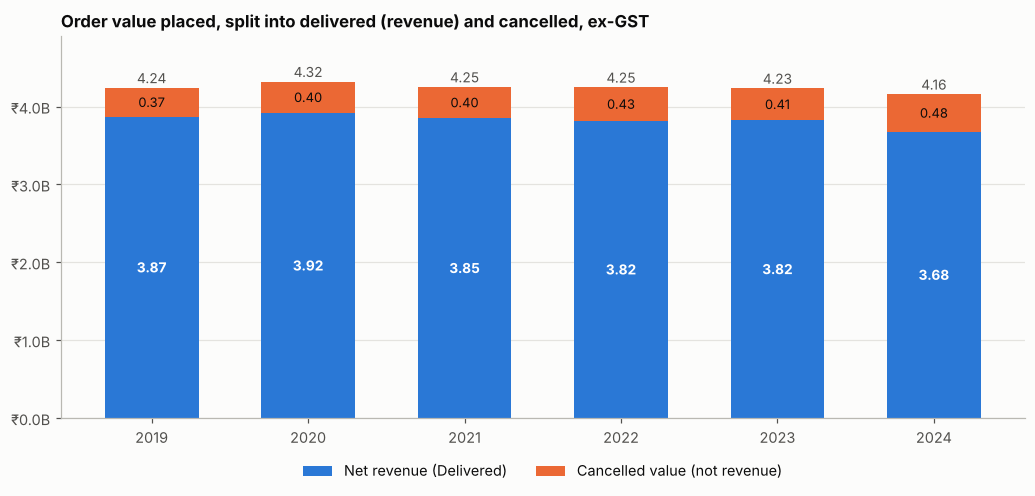

saved chart q1_01_placed_delivered_cancelled.png


In [5]:
fig, ax = figs(size=(9.5, 4.6))
x = chain.index.astype(str)
ax.bar(x, chain.net_revenue / 1e9, color=BLUE, width=.6, label="Net revenue (Delivered)")
ax.bar(x, chain.cancelled_value / 1e9, bottom=chain.net_revenue / 1e9, color=ORANGE, width=.6, label="Cancelled value (not revenue)")
for i, (yr, r) in enumerate(chain.iterrows()):
    ax.text(i, r.net_revenue / 2e9, f"{r.net_revenue/1e9:.2f}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(i, (r.net_revenue + r.cancelled_value / 2) / 1e9, f"{r.cancelled_value/1e9:.2f}", ha="center", va="center", color=INK, fontsize=8.5)
    ax.text(i, r.placed_value / 1e9 + .06, f"{r.placed_value/1e9:.2f}", ha="center", color=INK2, fontsize=9)
ax.set_ylim(0, 4.9); billions(ax, "y"); ax.grid(axis="x", visible=False)
ax.set_title("Order value placed, split into delivered (revenue) and cancelled, ex-GST")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(.5, -.08))
savefig(fig, "q1_01_placed_delivered_cancelled.png")

### A.2 Cross-check against an independent table: the invoices
The invoice table is a separate source. Its ex-GST value, grouped by the order's year, must equal net revenue.

In [6]:
inv["order_year"] = inv.order_date.dt.year
inv_rev = inv.groupby("order_year").total_order_value.sum()
check("net revenue by year == invoice table (ex-GST, by order year)", 0,
      float((chain.net_revenue - inv_rev).abs().max()), (chain.net_revenue - inv_rev).abs().max() < 1)
check("invoice orders == delivered orders", 0, len(set(inv.so_id) ^ set(deliv.so_id)), set(inv.so_id) == set(deliv.so_id))
print("Revenue does not depend on the 393 repeated-ID invoices (UI-01): it is computed from orders, and the invoice")
print("totals agree with it for every year, so the payment-attribution problem does not touch Q1.")
pd.DataFrame({"net_revenue_orders": chain.net_revenue, "invoice_value_ex_gst": inv_rev}).round(0)

Revenue does not depend on the 393 repeated-ID invoices (UI-01): it is computed from orders, and the invoice
totals agree with it for every year, so the payment-attribution problem does not touch Q1.


,net_revenue_orders,invoice_value_ex_gst
order_year,,
2019,3870016600,3870016600
2020,3917532120,3917532120
2021,3852479620,3852479620
2022,3816288220,3816288220
2023,3824675310,3824675310
2024,3677995560,3677995560


### A.3 Is the year basis safe? (partial years and year-boundary effects)
A drop in the last year can be an artefact if the year is incomplete, or if revenue is assigned to the wrong year. Two tests.

In [7]:
months = orders.groupby("order_year").order_month.nunique()
check("every year 2019-2024 contains all 12 order months", 72, int(months.sum()), (months == 12).all())
print("order_date range:", orders.order_date.min().date(), "to", orders.order_date.max().date())

deliv["delivery_year"] = deliv.delivery_date.dt.year
by_order = deliv.groupby("order_year").total_order_value.sum()
by_deliv = deliv.groupby("delivery_year").total_order_value.sum()
basis = pd.DataFrame({"net_revenue_by_order_year": by_order, "net_revenue_by_delivery_year": by_deliv}).fillna(0)
save(basis.round(0), "q1_year_basis_check.csv", index=True)
print("\nDelivery-year basis is NOT used:")
print(" - 2019 is understated (no orders from Dec 2018 exist in the data) and 2025 receives", inr_m(by_deliv.get(2025, 0)),
      "from late-December 2024 orders.")
print(" - The 2024 fall is present on either basis (order year:", f"{(by_order[2024]/by_order[2023]-1)*100:.1f}%",
      "vs 2023; delivery year:", f"{(by_deliv[2024]/by_deliv[2023]-1)*100:.1f}%).")
(basis / 1e9).round(3)

order_date range: 2019-01-01 to 2024-12-31
saved q1_year_basis_check.csv (7 rows)

Delivery-year basis is NOT used:
 - 2019 is understated (no orders from Dec 2018 exist in the data) and 2025 receives ₹71.0M from late-December 2024 orders.
 - The 2024 fall is present on either basis (order year: -3.8% vs 2023; delivery year: -4.0%).


,net_revenue_by_order_year,net_revenue_by_delivery_year
2019,3.87,3.82
2020,3.92,3.89
2021,3.85,3.83
2022,3.82,3.83
2023,3.83,3.84
2024,3.68,3.69
2025,0.00,0.07


# Part B — Is the decline real, and when did it happen?

In [8]:
aov = chain.net_revenue / chain.orders_delivered
r = chain.net_revenue
timing = pd.DataFrame([
    ["2019 -> 2023", r[2023] - r[2019], (r[2023] / r[2019] - 1) * 100],
    ["2023 -> 2024", r[2024] - r[2023], (r[2024] / r[2023] - 1) * 100],
    ["2019 -> 2024 (total)", r[2024] - r[2019], (r[2024] / r[2019] - 1) * 100],
], columns=["period", "change_inr", "change_pct"])
timing["share_of_total_decline_pct"] = timing.change_inr / (r[2024] - r[2019]) * 100
save(timing.round(2), "q1_timing_of_decline.csv")
print(f"Share of the 2019->2024 decline that happened in 2024 alone: {timing.share_of_total_decline_pct[1]:.1f}%")

# revenue = delivered orders x average order value: split the % change (log split, order independent)
dl = np.log(chain.orders_delivered[2024] / chain.orders_delivered[2019])
da = np.log(aov[2024] / aov[2019])
split_orders = dl / (dl + da) * 100
print(f"Delivered orders: {chain.orders_delivered[2019]:,} -> {chain.orders_delivered[2024]:,} ({(np.exp(dl)-1)*100:.1f}%) = {split_orders:.0f}% of the decline")
print(f"Average order value: {aov[2019]:,.0f} -> {aov[2024]:,.0f} ({(np.exp(da)-1)*100:.1f}%) = {100-split_orders:.0f}% of the decline")
check("delivered orders x average order value == net revenue (every year)", 0,
      float((chain.orders_delivered * aov - chain.net_revenue).abs().max()), ((chain.orders_delivered * aov - chain.net_revenue).abs() < 1).all())
timing.round(2)

saved q1_timing_of_decline.csv (3 rows)
Share of the 2019->2024 decline that happened in 2024 alone: 76.4%
Delivered orders: 3,031 -> 2,956 (-2.5%) = 49% of the decline
Average order value: 1,276,812 -> 1,244,247 (-2.6%) = 51% of the decline


,period,change_inr,change_pct,share_of_total_decline_pct
0,2019 -> 2023,-45341290,-1.17,23.61
1,2023 -> 2024,-146679750,-3.84,76.39
2,2019 -> 2024 (total),-192021040,-4.96,100.00


# Part C — Is there a price effect at all?
If a product's selling price never changes, the price effect is zero by construction and the whole movement must come from mix or volume.

In [9]:
pv = sales_d.groupby(["product_id", "order_year"]).unit_price.nunique()
n_vary = int((sales_d.groupby("product_id").unit_price.nunique() > 1).sum())
check("every product has one unit_price in every year", 0, n_vary, n_vary == 0 and pv.max() == 1)
price_tbl = sales_d.groupby(["product_id", "product_name"]).unit_price.agg(["min", "max"]).reset_index()
save(price_tbl, "q1_unit_price_check.csv")
print("Products whose unit_price differs between any two orders:", n_vary, "of", sales_d.product_id.nunique())
price_tbl.head(6)

saved q1_unit_price_check.csv (30 rows)
Products whose unit_price differs between any two orders: 0 of 30


,product_id,product_name,min,max
0,P001,Hydraulic Pump HP-300,24500,24500
1,P002,Engine Oil Filter OF-90,720,720
2,P003,Air Filter AF-120,1250,1250
3,P004,Track Chain TC-45,39800,39800
4,P005,Fuel Injector FI-220,8450,8450
5,P006,Alternator ALT-500,11200,11200


# Part D — Price / mix / volume bridge
For each product *p* with units *q* and realised price *p* = revenue / units:

* **Volume** = (Q₁ − Q₀) × average revenue per unit in the base year
* **Mix** = Σ p₀ × (q₁,p − Q₁ × share₀,p): units moving between cheap and expensive products at base-year prices
* **Price** = Σ (p₁ − p₀) × q₁,p

Volume + mix + price equals the revenue change exactly. Volume is then split into **orders placed**, **cancellation rate** and **basket size** (units per delivered order) with a log-mean split, so the result does not depend on the order in which the parts are taken.

In [10]:
placed = chain.orders_placed
deliv_n = chain.orders_delivered
units = sales_d.groupby("order_year").quantity.sum()
prod = sales_d.groupby(["order_year", "product_id"]).agg(q=("quantity", "sum"), r=("line_total", "sum"))

def logmean(a, b):
    return a if a == b else (a - b) / np.log(a / b)

def bridge(y0, y1):
    a, b = prod.loc[y0], prod.loc[y1]
    assert set(a.index) == set(b.index)
    b = b.loc[a.index]
    Q0, Q1, R0, R1 = a.q.sum(), b.q.sum(), a.r.sum(), b.r.sum()
    p0, p1 = a.r / a.q, b.r / b.q
    volume = (Q1 - Q0) * R0 / Q0
    mix = float((p0 * (b.q - Q1 * a.q / Q0)).sum())
    price = float(((p1 - p0) * b.q).sum())
    L = logmean(Q1, Q0); avg0 = R0 / Q0
    comps = {"placed_orders": np.log(placed[y1] / placed[y0]),
             "cancellation_rate": np.log((deliv_n[y1] / placed[y1]) / (deliv_n[y0] / placed[y0])),
             "basket_size": np.log((units[y1] / deliv_n[y1]) / (units[y0] / deliv_n[y0]))}
    split = {k: L * v * avg0 for k, v in comps.items()}
    return {"period": f"{y0}->{y1}", "start_revenue": R0, "end_revenue": R1, "change": R1 - R0,
            "price_effect": price, "mix_effect": mix, "volume_effect": volume,
            "vol_placed_orders": split["placed_orders"], "vol_cancellation_rate": split["cancellation_rate"],
            "vol_basket_size": split["basket_size"]}

br = pd.DataFrame([bridge(y, y + 1) for y in range(2019, 2024)] + [bridge(2019, 2024)])
check("price + mix + volume == revenue change (all periods)", 0,
      float((br.price_effect + br.mix_effect + br.volume_effect - br.change).abs().max()),
      ((br.price_effect + br.mix_effect + br.volume_effect - br.change).abs() < 0.01).all())
check("orders + cancellation rate + basket size == volume effect", 0,
      float((br.vol_placed_orders + br.vol_cancellation_rate + br.vol_basket_size - br.volume_effect).abs().max()),
      ((br.vol_placed_orders + br.vol_cancellation_rate + br.vol_basket_size - br.volume_effect).abs() < 0.01).all())
check("chained yearly changes sum to the 2019->2024 change", 0, round(br.change.iloc[:-1].sum() - br.change.iloc[-1], 2),
      abs(br.change.iloc[:-1].sum() - br.change.iloc[-1]) < 0.01)
save(br.round(0), "q1_price_mix_volume_bridge.csv")
show = br.copy(); num = [c for c in show.columns if c != "period"]; show[num] = (show[num] / 1e6).round(2)
print("INR millions. The last row is the direct 2019->2024 bridge (headline); the others are year-by-year.")
show

saved q1_price_mix_volume_bridge.csv (6 rows)
INR millions. The last row is the direct 2019->2024 bridge (headline); the others are year-by-year.


,period,start_revenue,end_revenue,change,price_effect,mix_effect,volume_effect,vol_placed_orders,vol_cancellation_rate,vol_basket_size
0,2019->2020,"3,870.02","3,917.53",47.52,0.00,-28.46,75.98,25.69,-16.67,66.96
1,2020->2021,"3,917.53","3,852.48",-65.05,0.00,4.02,-69.07,8.09,-8.09,-69.07
2,2021->2022,"3,852.48","3,816.29",-36.19,0.00,75.29,-111.49,-98.29,-15.88,2.68
3,2022->2023,"3,816.29","3,824.68",8.39,0.00,-36.83,45.21,77.65,17.52,-49.96
4,2023->2024,"3,824.68","3,678.00",-146.68,0.00,-57.34,-89.34,-34.04,-49.42,-5.87
5,2019->2024,"3,870.02","3,678.00",-192.02,0.00,-41.87,-150.15,-22.82,-72.26,-55.08


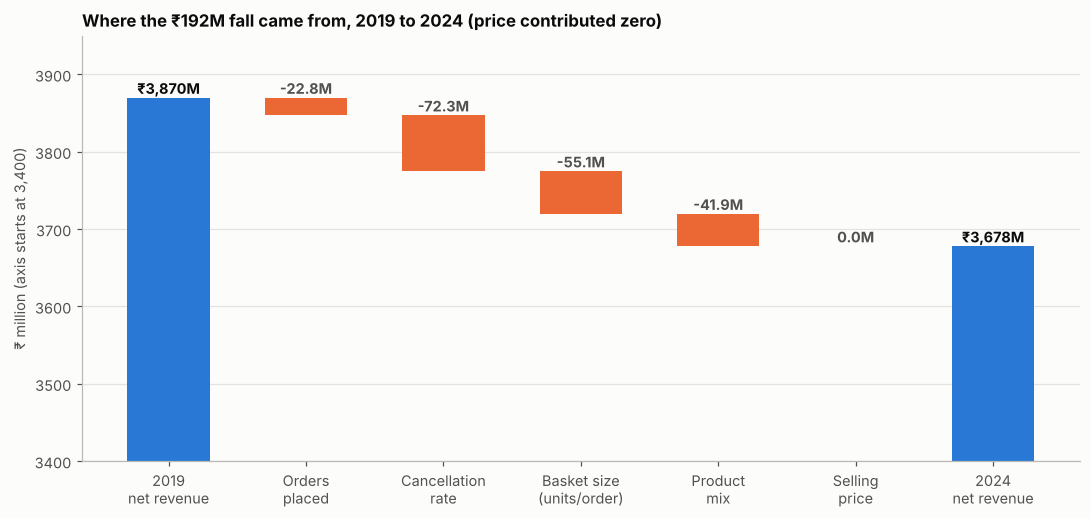

saved chart q1_02_bridge_2019_2024.png


In [11]:
h = br.iloc[-1]
steps = [("Orders\nplaced", h.vol_placed_orders), ("Cancellation\nrate", h.vol_cancellation_rate),
         ("Basket size\n(units/order)", h.vol_basket_size), ("Product\nmix", h.mix_effect), ("Selling\nprice", h.price_effect)]
fig, ax = figs(size=(10, 4.8))
s0 = h.start_revenue / 1e6
ax.bar(0, s0, color=BLUE, width=.6); ax.text(0, s0 + 5, f"₹{s0:,.0f}M", ha="center", color=INK, fontweight="bold")
cum = s0
for i, (lab, v) in enumerate(steps, 1):
    v = v / 1e6
    zero = abs(v) < .05
    ax.bar(i, .8 if zero else abs(v), bottom=(cum - .4) if zero else (cum if v >= 0 else cum + v), color=MUTED if zero else (AQUA if v > 0 else ORANGE), width=.6)
    ax.text(i, max(cum, cum + v) + 5, "0.0M" if zero else f"{v:+,.1f}M", ha="center", color=INK2, fontweight="bold")
    cum += v
e0 = h.end_revenue / 1e6
ax.bar(len(steps) + 1, e0, color=BLUE, width=.6); ax.text(len(steps) + 1, e0 + 5, f"₹{e0:,.0f}M", ha="center", color=INK, fontweight="bold")
ax.set_xticks(range(len(steps) + 2)); ax.set_xticklabels(["2019\nnet revenue"] + [s_[0] for s_ in steps] + ["2024\nnet revenue"])
ax.set_ylim(3400, 3950); ax.grid(axis="x", visible=False)
ax.set_ylabel("₹ million (axis starts at 3,400)")
ax.set_title(f"Where the ₹{-h.change/1e6:,.0f}M fall came from, 2019 to 2024 (price contributed zero)")
savefig(fig, "q1_02_bridge_2019_2024.png")

### D.1 Where the mix effect comes from

In [12]:
a, b = prod.loc[2019], prod.loc[2024].loc[prod.loc[2019].index]
Q0, Q1 = a.q.sum(), b.q.sum()
p0 = a.r / a.q
names = sales_d.drop_duplicates("product_id").set_index("product_id")[["product_name", "category"]]
mixdet = pd.DataFrame({"product": names.loc[a.index, "product_name"], "category": names.loc[a.index, "category"],
                       "unit_price": p0.round(2), "units_2019": a.q, "units_2024": b.q,
                       "unit_share_2019_pct": (a.q / Q0 * 100).round(2), "unit_share_2024_pct": (b.q / Q1 * 100).round(2)})
mixdet["share_change_pp"] = (mixdet.unit_share_2024_pct - mixdet.unit_share_2019_pct).round(2)
mixdet["mix_effect_inr"] = (p0 * (b.q - Q1 * a.q / Q0)).round(0)
mixdet = mixdet.sort_values("mix_effect_inr")
check("mix effect by product sums to the mix effect", 0, round(mixdet.mix_effect_inr.sum() - br.mix_effect.iloc[-1], 0),
      abs(mixdet.mix_effect_inr.sum() - br.mix_effect.iloc[-1]) < 5)
check("same 30 products sold in 2019 and 2024", 30, len(a), len(a) == 30 and set(a.index) == set(prod.loc[2024].index))
cat = mixdet.groupby("category").mix_effect_inr.sum().sort_values()
save(mixdet, "q1_mix_effect_by_product.csv"); save(cat.reset_index(), "q1_mix_effect_by_category.csv")
const_price = pd.Series({y: float((prod.loc[y].q * p0.reindex(prod.loc[y].index)).sum() / prod.loc[y].q.sum()) for y in range(2019, 2025)})
print("Mix effect by category (INR m):"); print((cat / 1e6).round(2).to_string())
print("\nAverage revenue per unit at constant 2019 prices (pure mix signal):"); print(const_price.round(0).to_string())
pd.concat([mixdet.head(4), mixdet.tail(4)])[["product", "category", "unit_price", "share_change_pp", "mix_effect_inr"]]

saved q1_mix_effect_by_product.csv (30 rows)
saved q1_mix_effect_by_category.csv (15 rows)
Mix effect by category (INR m):
category
Engine          -47.32
Hydraulic       -37.33
Undercarriage   -19.72
Brakes           -2.13
Cabin            -1.36
Pins & Bushes    -0.45
Belts             0.05
Lubricants        0.06
Attachments       0.08
Filters           0.43
Seals             0.65
Sensors           2.52
Cooling           6.09
Electrical        6.16
Transmission     50.40

Average revenue per unit at constant 2019 prices (pure mix signal):
2019   18,613.00
2020   18,478.00
2021   18,498.00
2022   18,870.00
2023   18,690.00
2024   18,403.00


,product,category,unit_price,share_change_pp,mix_effect_inr
product_id,,,,,
P019,Swing Motor SWM-350,Hydraulic,"39,800.00",-0.37,"-28,799,502.00"
P015,Engine Block EB-600,Engine,"119,000.00",-0.12,"-27,577,121.00"
P010,Turbocharger TB-900,Engine,"34,900.00",-0.32,"-22,728,507.00"
P004,Track Chain TC-45,Undercarriage,"39,800.00",-0.26,"-20,710,601.00"
P024,Track Roller TR-60,Undercarriage,"10,300.00",0.32,"6,682,106.00"
P030,Fuel Pump FP-350,Engine,"21,900.00",0.16,"7,077,898.00"
P006,Alternator ALT-500,Electrical,"11,200.00",0.58,"12,989,179.00"
P014,Transmission Assembly TA-800,Transmission,"83,500.00",0.31,"50,402,607.00"


# Part E — Demand or fulfilment?
Net revenue = placed value − cancelled value, so the question can also be asked from the order book: did customers order less, or were more of their orders cancelled?

In [13]:
d0, d1 = chain.loc[2019], chain.loc[2024]
view = pd.DataFrame({
    "2019": [d0.placed_value, d0.cancelled_value, d0.net_revenue],
    "2024": [d1.placed_value, d1.cancelled_value, d1.net_revenue],
}, index=["Placed value", "Cancelled value", "Net revenue"])
view["change_inr"] = view["2024"] - view["2019"]
view["change_pct"] = view.change_inr / view["2019"] * 100
save(view.round(2), "q1_order_book_view.csv", index=True)
cv = cancel.groupby("order_year").total_order_value.mean()
pv_all = orders.groupby("order_year").total_order_value.mean()
print(f"Placed value fell {inr_m(-view.change_inr['Placed value'])} ({view.change_pct['Placed value']:.1f}%); cancelled value rose "
      f"{inr_m(view.change_inr['Cancelled value'])} ({view.change_pct['Cancelled value']:.1f}%).")
print(f"Orders placed: {placed[2019]:,} -> {placed[2024]:,} ({(placed[2024]/placed[2019]-1)*100:.1f}%). "
      f"Cancellation rate: {chain.cancellation_rate_pct[2019]:.2f}% -> {chain.cancellation_rate_pct[2024]:.2f}%.")
print(f"Average value of a cancelled order: {cv[2019]:,.0f} (2019) -> {cv[2024]:,.0f} (2024); of all placed orders: {pv_all[2019]:,.0f} -> {pv_all[2024]:,.0f}.")
view.round(1)

saved q1_order_book_view.csv (3 rows)
Placed value fell ₹83.0M (-2.0%); cancelled value rose ₹109.1M (29.5%).
Orders placed: 3,336 -> 3,316 (-0.6%). Cancellation rate: 9.14% -> 10.86%.
Average value of a cancelled order: 1,213,570 (2019) -> 1,331,084 (2024); of all placed orders: 1,271,030 -> 1,253,675.


,2019,2024,change_inr,change_pct
Placed value,"4,240,155,300.00","4,157,185,730.00","-82,969,570.00",-2.00
Cancelled value,"370,138,700.00","479,190,170.00","109,051,470.00",29.50
Net revenue,"3,870,016,600.00","3,677,995,560.00","-192,021,040.00",-5.00


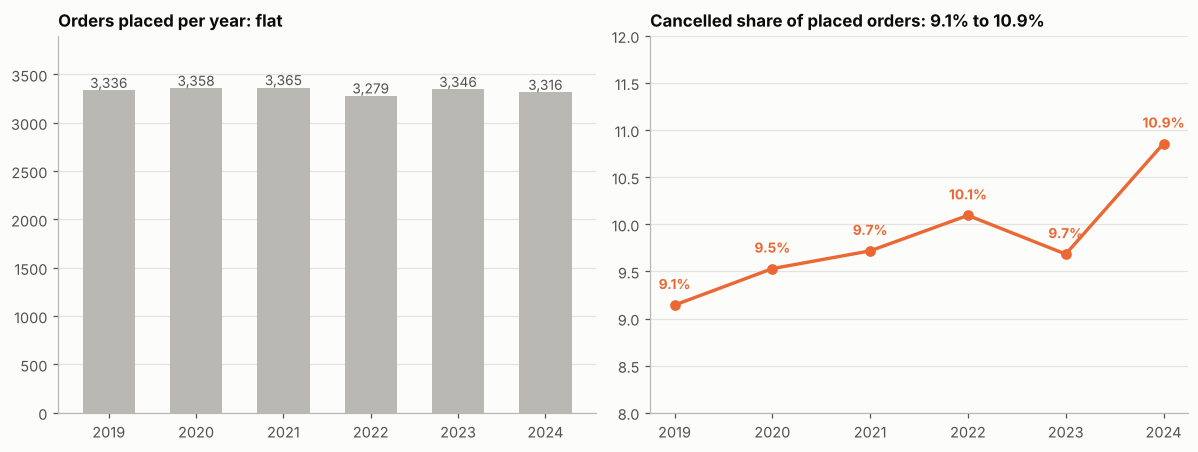

saved chart q1_03_orders_and_cancellations.png


In [14]:
fig, axs = figs(1, 2, size=(11, 4.2))
yrs = chain.index
axs[0].bar(yrs.astype(str), placed.values, color=MUTED, width=.6)
for i, v in enumerate(placed.values):
    axs[0].text(i, v + 25, f"{v:,}", ha="center", color=INK2, fontsize=9)
axs[0].set_ylim(0, 3900); axs[0].grid(axis="x", visible=False)
axs[0].set_title("Orders placed per year: flat")
axs[1].plot(yrs.astype(str), chain.cancellation_rate_pct.values, marker="o", color=ORANGE, lw=2.2)
for i, v in enumerate(chain.cancellation_rate_pct.values):
    axs[1].text(i, v + .17, f"{v:.1f}%", ha="center", color=ORANGE, fontsize=9, fontweight="bold")
axs[1].set_ylim(8, 12); axs[1].grid(axis="x", visible=False)
axs[1].set_title(f"Cancelled share of placed orders: {chain.cancellation_rate_pct[2019]:.1f}% to {chain.cancellation_rate_pct[2024]:.1f}%")
savefig(fig, "q1_03_orders_and_cancellations.png")

# Part F — Which claims survive a noise test?
The movements are small relative to the spread of individual order values, so each claim is tested before it is called a finding. Tests treat orders as independent.

In [15]:
rng = np.random.default_rng(42)
v19 = deliv[deliv.order_year == 2019].total_order_value.values
v24 = deliv[deliv.order_year == 2024].total_order_value.values

t_aov = stats.ttest_ind(v19, v24, equal_var=False)                                   # (1) order value 2019 vs 2024
lr_aov = stats.linregress(deliv.order_year, deliv.total_order_value)                 # (2) order value trend, all years
boot = np.array([rng.choice(v24, len(v24)).sum() / rng.choice(v19, len(v19)).sum() - 1 for _ in range(5000)]) * 100
lo, hi = np.percentile(boot, [2.5, 97.5])                                            # (3) bootstrap, revenue change

pr = sales_d.groupby("product_id").unit_price.first()                                # (4) permutation test, mix effect
sub = sales_d[sales_d.order_year.isin([2019, 2024])]
M = sub.pivot_table(index="so_id", columns="product_id", values="quantity", aggfunc="sum", fill_value=0)[pr.index]
lab = sub.drop_duplicates("so_id").set_index("so_id").loc[M.index, "order_year"].values
Mv, pvv = M.values.astype(float), pr.values.astype(float)
def mix_stat(labels):
    q0 = Mv[labels == 2019].sum(0); q1 = Mv[labels == 2024].sum(0)
    return float(pvv @ q1 - q1.sum() / q0.sum() * (pvv @ q0))
obs_mix = mix_stat(lab)
perm = np.array([mix_stat(rng.permutation(lab)) for _ in range(5000)])
p_mix = float((np.abs(perm) >= abs(obs_mix)).mean())
check("permutation statistic reproduces the bridge mix effect", 0, round(obs_mix - br.mix_effect.iloc[-1], 2), abs(obs_mix - br.mix_effect.iloc[-1]) < 1)

sub2 = sales_d[sales_d.order_year.isin([2023, 2024])]                                # (4b) same test for the 2023->2024 step alone
M2 = sub2.pivot_table(index="so_id", columns="product_id", values="quantity", aggfunc="sum", fill_value=0)[pr.index]
lab2 = sub2.drop_duplicates("so_id").set_index("so_id").loc[M2.index, "order_year"].values
Mv2 = M2.values.astype(float)
def mix_stat2(labels):
    q0 = Mv2[labels == 2023].sum(0); q1 = Mv2[labels == 2024].sum(0)
    return float(pvv @ q1 - q1.sum() / q0.sum() * (pvv @ q0))
obs_mix2 = mix_stat2(lab2)
perm2 = np.array([mix_stat2(rng.permutation(lab2)) for _ in range(5000)])
p_mix2 = float((np.abs(perm2) >= abs(obs_mix2)).mean())
mix_2324 = float(br.loc[br.period == "2023->2024", "mix_effect"].iloc[0])
check("2023->2024 permutation statistic reproduces the bridge mix effect", 0, round(obs_mix2 - mix_2324, 2), abs(obs_mix2 - mix_2324) < 1)
check("2023->2024 mix effect is not distinguishable from noise (p > 0.05)", ">0.05", round(p_mix2, 3), p_mix2 > 0.05)

tab = np.array([[chain.orders_cancelled[2019], chain.orders_delivered[2019]], [chain.orders_cancelled[2024], chain.orders_delivered[2024]]])
chi = stats.chi2_contingency(tab)                                                    # (5) cancellation rate 2019 vs 2024
chi_all = stats.chi2_contingency(np.c_[chain.orders_cancelled, chain.orders_delivered])        # (6a) could all six years share one rate?
_n, _x, _sc = chain.orders_placed.values, chain.orders_cancelled.values, np.arange(6)               # (6b) Cochran-Armitage linear trend
_p = _x.sum() / _n.sum()
z_ca = (_sc * (_x - _n * _p)).sum() / np.sqrt(_p * (1 - _p) * ((_n * _sc ** 2).sum() - (_n * _sc).sum() ** 2 / _n.sum()))
p_ca = 2 * (1 - stats.norm.cdf(abs(z_ca)))
c19 = cancel[cancel.order_year == 2019].total_order_value.values
c24 = cancel[cancel.order_year == 2024].total_order_value.values
t_c = stats.ttest_ind(c19, c24, equal_var=False)                                     # (7) value of a cancelled order

pl19 = orders[orders.order_year == 2019].total_order_value.values                  # (8) placed value (demand before cancellations)
pl24 = orders[orders.order_year == 2024].total_order_value.values
boot_pl = np.array([rng.choice(pl24, len(pl24)).sum() / rng.choice(pl19, len(pl19)).sum() - 1 for _ in range(5000)]) * 100
lo_pl, hi_pl = np.percentile(boot_pl, [2.5, 97.5])
v23 = deliv[deliv.order_year == 2023].total_order_value.values                     # (9) the 2023->2024 step on its own
boot_step = np.array([rng.choice(v24, len(v24)).sum() / rng.choice(v23, len(v23)).sum() - 1 for _ in range(5000)]) * 100
lo_st, hi_st = np.percentile(boot_step, [2.5, 97.5])
check("2023->2024 bootstrap observed change matches the bridge (-3.8%)", -3.84, round((v24.sum() / v23.sum() - 1) * 100, 2), abs((v24.sum() / v23.sum() - 1) * 100 + 3.84) < 0.01)

def verdict(p): return "Distinguishable from noise" if p < 0.05 else "Not distinguishable from noise"
sig = pd.DataFrame([
    ["Average order value, 2019 vs 2024 (Welch t)", f"{v19.mean():,.0f} vs {v24.mean():,.0f}", t_aov.statistic, t_aov.pvalue, verdict(t_aov.pvalue)],
    ["Order-value trend, all delivered orders (OLS slope per year)", f"{lr_aov.slope:,.0f} per year", lr_aov.slope / lr_aov.stderr, lr_aov.pvalue, verdict(lr_aov.pvalue)],
    ["Net revenue change 2019->2024, bootstrap 95% interval (%)", f"{(v24.sum()/v19.sum()-1)*100:.2f}% observed; [{lo:.2f}, {hi:.2f}]", np.nan, np.nan,
     "Interval excludes zero (narrowly)" if hi < 0 else "Interval includes zero"],
    ["Placed value (demand before cancellations) change 2019->2024, bootstrap 95% interval (%)", f"{(pl24.sum()/pl19.sum()-1)*100:.2f}% observed; [{lo_pl:.2f}, {hi_pl:.2f}]", np.nan, np.nan,
     "Interval excludes zero" if (hi_pl < 0 or lo_pl > 0) else "Interval includes zero (demand is flat)"],
    ["Net revenue change 2023->2024 step alone, bootstrap 95% interval (%)", f"{(v24.sum()/v23.sum()-1)*100:.2f}% observed; [{lo_st:.2f}, {hi_st:.2f}]", np.nan, np.nan,
     "Interval excludes zero" if (hi_st < 0 or lo_st > 0) else "Interval includes zero (step not distinguishable from year-to-year variation)"],
    ["Product-mix effect 2019->2024, permutation (5,000 shuffles)", f"{obs_mix/1e6:,.1f}M; shuffled 95% range [{np.percentile(perm,2.5)/1e6:,.1f}M, {np.percentile(perm,97.5)/1e6:,.1f}M]", np.nan, p_mix, verdict(p_mix)],
    ["Product-mix effect 2023->2024 step only, permutation (5,000 shuffles)", f"{obs_mix2/1e6:,.1f}M; shuffled 95% range [{np.percentile(perm2,2.5)/1e6:,.1f}M, {np.percentile(perm2,97.5)/1e6:,.1f}M]", np.nan, p_mix2, verdict(p_mix2)],
    ["Cancellation rate, six-year homogeneity (chi-square, df 5)", "could all six years share one rate?", chi_all[0], chi_all[1], verdict(chi_all[1])],
    ["Cancellation rate, linear trend over six years (Cochran-Armitage)", f"z = {z_ca:.2f}", z_ca, p_ca, "Weak trend: detectable, but no single year differs"],
    ["Cancellation rate, 2019 vs 2024 endpoints (chi-square)", f"{chain.cancellation_rate_pct[2019]:.2f}% vs {chain.cancellation_rate_pct[2024]:.2f}%", chi[0], chi[1], "Tentative: endpoints chosen after looking"],
    ["Value of a cancelled order, 2019 vs 2024 (Welch t)", f"{c19.mean():,.0f} vs {c24.mean():,.0f}", t_c.statistic, t_c.pvalue, verdict(t_c.pvalue)],
], columns=["test", "result", "statistic", "p_value", "verdict"])
save(sig.round(4), "q1_significance_tests.csv")
sig.round(4)

saved q1_significance_tests.csv (11 rows)


,test,result,statistic,p_value,verdict
0,"Average order value, 2019 vs 2024 (Welch t)","1,276,812 vs 1,244,247",1.17,0.24,Not distinguishable from noise
1,"Order-value trend, all delivered orders (OLS s...","-5,916 per year",-1.26,0.21,Not distinguishable from noise
2,"Net revenue change 2019->2024, bootstrap 95% i...","-4.96% observed; [-8.99, -0.84]",NaN,NaN,Interval excludes zero (narrowly)
3,Placed value (demand before cancellations) cha...,"-1.96% observed; [-5.82, 2.23]",NaN,NaN,Interval includes zero (demand is flat)
4,"Net revenue change 2023->2024 step alone, boot...","-3.84% observed; [-7.86, 0.51]",NaN,NaN,Interval includes zero (step not distinguishab...
5,"Product-mix effect 2019->2024, permutation (5,...","-41.9M; shuffled 95% range [-116.4M, 117.0M]",NaN,0.47,Not distinguishable from noise
6,"Product-mix effect 2023->2024 step only, permu...","-57.3M; shuffled 95% range [-118.9M, 118.1M]",NaN,0.34,Not distinguishable from noise
7,"Cancellation rate, six-year homogeneity (chi-s...",could all six years share one rate?,6.45,0.27,Not distinguishable from noise
8,"Cancellation rate, linear trend over six years...",z = 2.18,2.18,0.03,"Weak trend: detectable, but no single year dif..."
9,"Cancellation rate, 2019 vs 2024 endpoints (chi...",9.14% vs 10.86%,5.24,0.02,Tentative: endpoints chosen after looking


# Part G — Real terms (indicative, external assumption)
Selling prices never changed, so inflation-adjusted revenue falls much faster than nominal revenue. **This part depends on an outside series and is therefore reported as indicative, not as a finding.**

Annual India CPI inflation used for 2020 to 2024: 6.6%, 5.2%, 6.7%, 5.6%, 4.6% (focus-economics.com, macrotrends.net). It is general consumer inflation, **not** a price index for heavy-machinery parts, so it shows the order of magnitude. A flat-inflation range (2% to 6% a year) is shown beside it so the conclusion does not hinge on this one series.

In [16]:
cpi = {2019: 0.0, 2020: 6.6, 2021: 5.2, 2022: 6.7, 2023: 5.6, 2024: 4.6}      # 2019 is the base year
idx = {}; lvl = 1.0
for y in range(2019, 2025):
    lvl *= 1 + cpi[y] / 100; idx[y] = lvl
idx = pd.Series(idx)
rev = chain.net_revenue
real = pd.DataFrame({"nominal_revenue": rev, "price_index_2019_100": (idx * 100).round(2)})
real["revenue_in_2019_rupees"] = (rev / idx).round(0)
real["nominal_vs_2019_pct"] = ((rev / rev[2019] - 1) * 100).round(2)
real["real_vs_2019_pct"] = ((real.revenue_in_2019_rupees / real.revenue_in_2019_rupees[2019] - 1) * 100).round(2)
real["revenue_per_unit_nominal"] = (rev / units).round(2)
real["revenue_per_unit_in_2019_rupees"] = (rev / units / idx).round(2)
real["real_price_vs_2019_pct"] = ((real.revenue_per_unit_in_2019_rupees / real.revenue_per_unit_in_2019_rupees[2019] - 1) * 100).round(2)
check("real revenue in 2019 equals nominal revenue in 2019", 0, round(real.revenue_in_2019_rupees[2019] - rev[2019], 2), abs(real.revenue_in_2019_rupees[2019] - rev[2019]) < 1)
save(real, "q1_real_terms_revenue.csv", index=True)

sens = pd.DataFrame({"assumed_annual_inflation_pct": [0, 2, 3, 4, 5, 6]})
sens["real_change_2024_vs_2019_pct"] = [round(((rev[2024] / rev[2019]) / (1 + p / 100) ** 5 - 1) * 100, 1) for p in sens.assumed_annual_inflation_pct]
save(sens, "q1_inflation_sensitivity.csv")
keep = rev[2019] * idx[2024]
print(f"Revenue needed in 2024 to keep pace with the CPI series: {inr_b(keep)} vs actual {inr_b(rev[2024])} (shortfall {inr_b(keep - rev[2024])})")
display(real); display(sens)

saved q1_real_terms_revenue.csv (6 rows)
saved q1_inflation_sensitivity.csv (6 rows)
Revenue needed in 2024 to keep pace with the CPI series: ₹5.12B vs actual ₹3.68B (shortfall ₹1.44B)


,nominal_revenue,price_index_2019_100,revenue_in_2019_rupees,nominal_vs_2019_pct,real_vs_2019_pct,revenue_per_unit_nominal,revenue_per_unit_in_2019_rupees,real_price_vs_2019_pct
2019,3870016600,100.00,"3,870,016,600.00",0.00,0.00,"18,612.56","18,612.56",0.00
2020,3917532120,106.60,"3,674,983,227.00",1.23,-5.04,"18,478.31","17,334.25",-6.87
2021,3852479620,112.14,"3,435,321,642.00",-0.45,-11.23,"18,497.61","16,494.64",-11.38
2022,3816288220,119.66,"3,189,361,907.00",-1.39,-17.59,"18,869.91","15,770.03",-15.27
2023,3824675310,126.36,"3,026,866,663.00",-1.17,-21.79,"18,689.96","14,791.32",-20.53
2024,3677995560,132.17,"2,782,775,903.00",-4.96,-28.09,"18,403.04","13,923.77",-25.19


,assumed_annual_inflation_pct,real_change_2024_vs_2019_pct
0,0,-5.00
1,2,-13.90
2,3,-18.00
3,4,-21.90
4,5,-25.50
5,6,-29.00


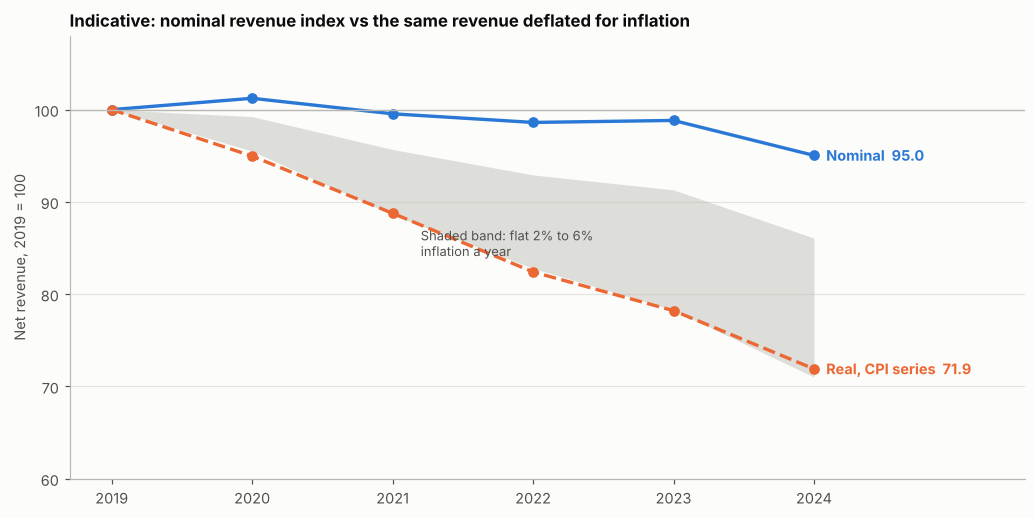

saved chart q1_04_nominal_vs_real_indicative.png


In [17]:
fig, ax = figs(size=(9.5, 4.8))
yrs = np.arange(2019, 2025)
nom = (rev / rev[2019] * 100).values
rl = (real.revenue_in_2019_rupees / real.revenue_in_2019_rupees[2019] * 100).values
low = nom / (1.02 ** (yrs - 2019)); high = nom / (1.06 ** (yrs - 2019))
ax.fill_between(yrs, high, low, color=MUTED, alpha=.45, lw=0)
ax.plot(yrs, nom, marker="o", color=BLUE, lw=2.2); ax.plot(yrs, rl, marker="o", color=ORANGE, lw=2.2, ls="--")
ax.axhline(100, color=MUTED, lw=.9)
ax.annotate(f"Nominal  {nom[-1]:.1f}", (2024, nom[-1]), xytext=(8, 0), textcoords="offset points", color=BLUE, fontweight="bold", va="center")
ax.annotate(f"Real, CPI series  {rl[-1]:.1f}", (2024, rl[-1]), xytext=(8, 0), textcoords="offset points", color=ORANGE, fontweight="bold", va="center")
ax.annotate("Shaded band: flat 2% to 6%\ninflation a year", (2021.2, (low[2] + high[2]) / 2 - 8), color=INK2, fontsize=8.5)
ax.set_xlim(2018.7, 2025.5); ax.set_ylim(60, 108); ax.set_xticks(yrs); ax.grid(axis="x", visible=False)
ax.set_ylabel("Net revenue, 2019 = 100")
ax.set_title("Indicative: nominal revenue index vs the same revenue deflated for inflation")
savefig(fig, "q1_04_nominal_vs_real_indicative.png")

# Validation report

In [18]:
rep = pd.DataFrame(checks, columns=["Check_Item", "Expected", "Actual", "Status"])
rep.to_csv("validation_report_week04_q1.csv", index=False)
print(f"{(rep.Status == 'PASS').sum()} / {len(rep)} checks passed")
rep.to_string(index=False)

26 / 26 checks passed


'                                                        Check_Item Expected     Actual Status\n                                           sales rows (line grain)   130402 130,402.00   PASS\n                              sales key (so_id,line_number) unique        0       0.00   PASS\n                                                     unique orders    20000  20,000.00   PASS\n                                                      invoice rows    18033  18,033.00   PASS\n                                        no ambiguous _x/_y columns        0       0.00   PASS\n                   order header total == sum of lines (all orders)        0       0.00   PASS\n                               delivered + cancelled == all orders    20000  20,000.00   PASS\n           net revenue (delivered lines) == delivered order totals        0       0.00   PASS\n        placed value - cancelled value == net revenue (every year)        0       0.00   PASS\n             net revenue by year == Week 3 kpi_re